# ML Lab 06 (Lab Task 1: Metrics Practice)

**Dataset:** Breast Cancer Wisconsin (binary classification, built into scikit-learn)
**Model:** Logistic Regression

Steps covered:
1. Train a classification model
2. Generate predictions
3. Print the confusion matrix
4. Calculate accuracy, precision, recall, specificity and F1-score
5. Calculate ROC-AUC using prediction probabilities
6. Explain which metric is most appropriate for the dataset and why

## Setup: Imports and Data

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (confusion_matrix, accuracy_score, precision_score,
                             recall_score, f1_score, roc_auc_score, roc_curve,
                             ConfusionMatrixDisplay)

In [ ]:
data = load_breast_cancer()
X = pd.DataFrame(data.data, columns=data.feature_names)

y = pd.Series(1 - data.target, name="malignant")

print("Samples :", X.shape[0])
print("Features:", X.shape[1])
print()
print("Class counts (1 = malignant, 0 = benign):")
print(y.value_counts().sort_index())
print()
print("Class proportions:")
print(y.value_counts(normalize=True).sort_index().round(3))

Samples : 569
Features: 30

Class counts (1 = malignant, 0 = benign):
malignant
0    357
1    212
Name: count, dtype: int64

Class proportions:
malignant
0    0.627
1    0.373
Name: proportion, dtype: float64


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (455, 30) | Test: (114, 30)


## Step 1: Train a Classification Model

In [ ]:
model = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", LogisticRegression(max_iter=1000, random_state=42)),
])

model.fit(X_train, y_train)
print("Model trained.")

Model trained.


## Step 2: Generate Predictions

In [ ]:
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

print("First 10 actual   :", y_test.values[:10])
print("First 10 predicted:", y_pred[:10])
print("First 10 probability of malignant:", y_prob[:10].round(3))

First 10 actual   : [0 1 0 1 0 0 1 0 0 0]
First 10 predicted: [0 1 0 1 1 0 1 0 0 0]
First 10 probability of malignant: [0.    1.    0.043 0.576 0.509 0.001 0.762 0.001 0.001 0.011]


## Step 3: Confusion Matrix
Rows are the actual class and columns are the predicted class.

In [ ]:
cm = confusion_matrix(y_test, y_pred)
print(cm)
print()
print(pd.DataFrame(
    cm,
    index=["Actual 0 (Benign)", "Actual 1 (Malignant)"],
    columns=["Predicted 0 (Benign)", "Predicted 1 (Malignant)"],
))

tn, fp, fn, tp = cm.ravel()
print()
print(f"TN = {tn}  (benign correctly predicted as benign)")
print(f"FP = {fp}  (benign wrongly predicted as malignant)")
print(f"FN = {fn}  (malignant wrongly predicted as benign)")
print(f"TP = {tp}  (malignant correctly predicted as malignant)")

[[71  1]
 [ 3 39]]

                      Predicted 0 (Benign)  Predicted 1 (Malignant)
Actual 0 (Benign)                       71                        1
Actual 1 (Malignant)                     3                       39

TN = 71  (benign correctly predicted as benign)
FP = 1  (benign wrongly predicted as malignant)
FN = 3  (malignant wrongly predicted as benign)
TP = 39  (malignant correctly predicted as malignant)


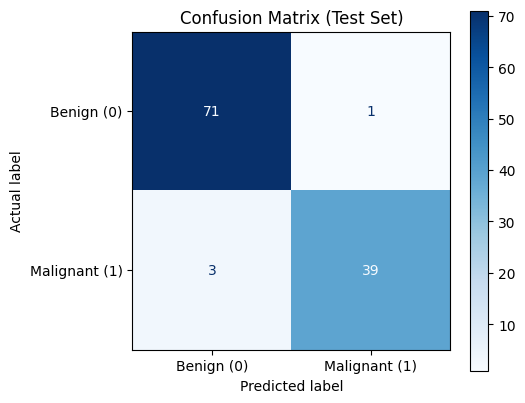

In [ ]:
# Confusion matrix plot (counts)
fig, ax = plt.subplots(figsize=(5.5, 4.5))
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Benign (0)", "Malignant (1)"],
)
disp.plot(ax=ax, cmap="Blues", colorbar=True, values_format="d")
ax.set_title("Confusion Matrix (Test Set)")
ax.set_xlabel("Predicted label")
ax.set_ylabel("Actual label")
plt.tight_layout()
plt.show()

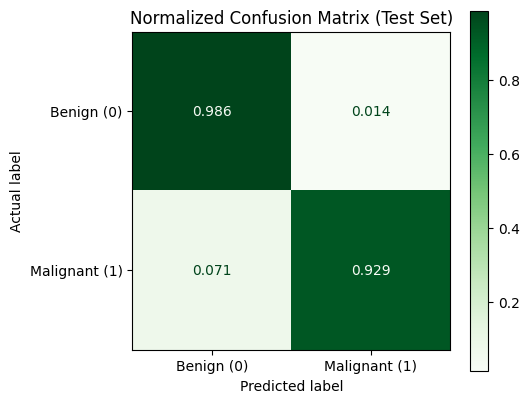

In [ ]:
# Normalized confusion matrix plot (each row sums to 1, so the diagonal shows per-class rates)
cm_norm = confusion_matrix(y_test, y_pred, normalize="true")

fig, ax = plt.subplots(figsize=(5.5, 4.5))
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_norm,
    display_labels=["Benign (0)", "Malignant (1)"],
)
disp.plot(ax=ax, cmap="Greens", colorbar=True, values_format=".3f")
ax.set_title("Normalized Confusion Matrix (Test Set)")
ax.set_xlabel("Predicted label")
ax.set_ylabel("Actual label")
plt.tight_layout()
plt.show()

## Step 4: Accuracy, Precision, Recall, Specificity and F1-Score

| Metric | Formula | Question it answers |
|---|---|---|
| Accuracy | (TP + TN) / (TP + TN + FP + FN) | Overall, how many predictions were correct? |
| Precision | TP / (TP + FP) | Of the cases predicted malignant, how many really were? |
| Recall | TP / (TP + FN) | Of the truly malignant cases, how many did we find? |
| Specificity | TN / (TN + FP) | Of the truly benign cases, how many did we correctly clear? |
| F1-Score | 2 × (Precision × Recall) / (Precision + Recall) | How balanced are precision and recall? |

In [ ]:
accuracy    = accuracy_score(y_test, y_pred)
precision   = precision_score(y_test, y_pred)
recall      = recall_score(y_test, y_pred)
specificity = tn / (tn + fp)      # scikit-learn has no direct specificity function
f1          = f1_score(y_test, y_pred)

print("Accuracy   :", round(accuracy, 3))
print("Precision  :", round(precision, 3))
print("Recall     :", round(recall, 3))
print("Specificity:", round(specificity, 3))
print("F1-Score   :", round(f1, 3))

Accuracy   : 0.965
Precision  : 0.975
Recall     : 0.929
Specificity: 0.986
F1-Score   : 0.951


In [ ]:
# Sanity check: recompute every metric by hand from the confusion matrix
print("Accuracy    (manual):", round((tp + tn) / (tp + tn + fp + fn), 3))
print("Precision   (manual):", round(tp / (tp + fp), 3))
print("Recall      (manual):", round(tp / (tp + fn), 3))
print("Specificity (manual):", round(tn / (tn + fp), 3))
prec_m, rec_m = tp / (tp + fp), tp / (tp + fn)
print("F1-Score    (manual):", round(2 * prec_m * rec_m / (prec_m + rec_m), 3))

Accuracy    (manual): 0.965
Precision   (manual): 0.975
Recall      (manual): 0.929
Specificity (manual): 0.986
F1-Score    (manual): 0.951


## Step 5: ROC-AUC Using Prediction Probabilities
ROC-AUC must be computed from predicted **probabilities** (or scores), not from hard 0/1 labels, because it measures how well the model ranks positives above negatives across all possible thresholds.

In [ ]:
auc = roc_auc_score(y_test, y_prob)
print("ROC-AUC:", round(auc, 3))
print()
print("Interpretation: 1.0 = perfect separation, 0.5 = random guessing.")

ROC-AUC: 0.996

Interpretation: 1.0 = perfect separation, 0.5 = random guessing.


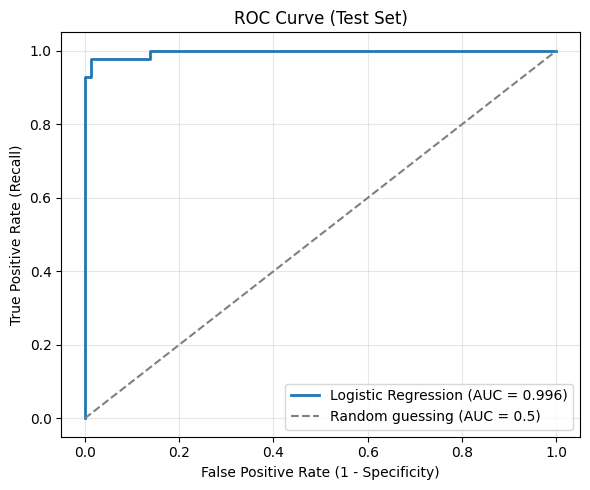

In [ ]:
# ROC curve: True Positive Rate vs False Positive Rate across all thresholds
fpr, tpr, thresholds = roc_curve(y_test, y_prob)

fig, ax = plt.subplots(figsize=(6, 5))
ax.plot(fpr, tpr, linewidth=2, label=f"Logistic Regression (AUC = {auc:.3f})")
ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random guessing (AUC = 0.5)")
ax.set_xlabel("False Positive Rate (1 - Specificity)")
ax.set_ylabel("True Positive Rate (Recall)")
ax.set_title("ROC Curve (Test Set)")
ax.legend(loc="lower right")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
# Final summary table
summary = pd.Series({
    "Accuracy": accuracy,
    "Precision": precision,
    "Recall (Sensitivity)": recall,
    "Specificity": specificity,
    "F1-Score": f1,
    "ROC-AUC": auc,
}).round(3)
print(summary.to_string())

Accuracy                0.965
Precision               0.975
Recall (Sensitivity)    0.929
Specificity             0.986
F1-Score                0.951
ROC-AUC                 0.996


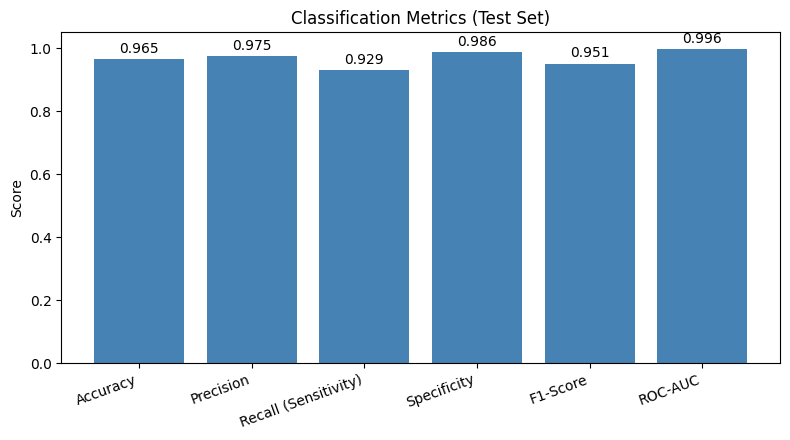

In [ ]:
# Bar chart of all metrics
fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.bar(summary.index, summary.values, color="steelblue")
ax.set_ylim(0, 1.05)
ax.set_ylabel("Score")
ax.set_title("Classification Metrics (Test Set)")
for b in bars:
    ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.01,
            f"{b.get_height():.3f}", ha="center", va="bottom")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

## Step 6: Which Metric Is Most Appropriate and Why?

**Context:** The task is to detect malignant tumors (positive class = malignant). The two kinds of errors have very different costs:

| Error | Meaning | Consequence |
|---|---|---|
| False Negative (FN) | A malignant tumor is predicted as benign | A patient with cancer is sent home untreated. Very costly and potentially fatal. |
| False Positive (FP) | A benign tumor is predicted as malignant | The patient undergoes extra tests or a biopsy. Stressful, but usually recoverable. |

**Most appropriate metric: Recall (Sensitivity).**
Recall = TP / (TP + FN) directly measures how many truly malignant cases the model catches, so it penalizes the most dangerous error (false negatives). In a screening setting, we want recall as high as possible.

**Why not accuracy alone?**
Accuracy treats both error types equally and is dominated by the larger class (benign, about 63% of the data). A model could look good on accuracy while still missing malignant cases.

**Supporting metrics:**
- **Precision** should be monitored alongside recall so that the model does not flag nearly everyone as malignant (which would flood patients with unnecessary follow-ups).
- **F1-Score** is useful as a single number when we need to balance recall and precision.
- **Specificity** tells us how well benign cases are cleared.
- **ROC-AUC** is threshold-independent. It tells us how well the model separates the two classes overall, and it helps when choosing a decision threshold (for example, lowering the threshold below 0.5 to boost recall at the cost of some precision).

**Conclusion:** Recall is the primary metric for this dataset because missing a cancer case is far worse than a false alarm. Precision, F1 and ROC-AUC are used as secondary checks to make sure the high recall is not achieved by simply predicting "malignant" for everyone.